In [1]:
import torch
import torch.distributions as dist
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

from engression.loss_func import energy_loss, energy_loss_two_sample

from sem2.model.models.base import SEM2
from sem2.model.components.nn_models import _MLP as MLP
from Amari_error import Amari_error

In [3]:
def generate_data(n_samples=5000, A_true=None, Sigma=None):
    A_true = torch.tensor(A_true,dtype=torch.float32) if isinstance(A_true, np.ndarray) else A_true
    n_features, n_sources = A_true.shape
    S1_true = dist.Gamma(2.0, 1.0).sample((n_samples,))
    S2_true = dist.Beta(2.0, 5.0).sample((n_samples,))
    S_true = torch.stack([S1_true, S2_true], dim=0)  # Shape: (n_sources, n_samples)
    X_clean = A_true @ S_true  # Shape: (n_features, n_samples)

    if Sigma is None:
        X_noisy = X_clean.T
    else:
        Sigma = torch.tensor(Sigma,dtype=torch.float32) if isinstance(Sigma, np.ndarray) else Sigma
        noise_dist = dist.MultivariateNormal(loc=torch.zeros(n_features),covariance_matrix=Sigma)
        noise = noise_dist.sample((n_samples,))  # Shape: (n_samples, n_features)
        X_noisy = X_clean.T + noise

    return X_noisy  # Shapes: (n_samples, n_features)


def generate_mixing_matrix(n,d):
    sigma = np.random.uniform(1, d, n-2) 
    sigma = np.concatenate([sigma, [1, d]])  
    np.random.shuffle(sigma) 
    Sigma = np.diag(sigma)
    R1 = np.random.randn(n, n)
    U, _ = np.linalg.qr(R1)
    R2 = np.random.randn(n, n)
    V, _ = np.linalg.qr(R2)
    A = U @ Sigma @ V.T
    return torch.tensor(A,dtype=torch.float32)

In [5]:
n_components=2
cdn=3
A_true = generate_mixing_matrix(n_components, cdn) 
X = generate_data(n_samples=5000, A_true=A_true, Sigma=None)

In [7]:
fastica = FastICA(n_components=n_components)
fastica.fit(X) 
A_fast = fastica.mixing_
Amari_error(A_fast,A_true)

0.14406091993726294

In [ ]:
## the distributions of S1,S2 are known; noise-free ICA

In [23]:
model_formula_X = "x1 <- s1 + s2; x2 <- s1 + s2"
model_formula_S = "s1 ~ Gamma(2.0,1.0); s2 ~ Beta(2.0,5.0);"
model_formula = model_formula_S + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3)
model.train()
niter = 4000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 3)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1/3)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy()
            A_hat[j, :] = weights.flatten()

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

with torch.no_grad():  
    X_0p = generate_data(n_samples=20000, A_true=A_true)
    X_hat = generate_data(n_samples=20000, A_true=A_hat)
    loss_0, s1_0, s2_0 = energy_loss(X, X_0p)
    loss_1, s1_1, s2_1 = energy_loss(X, X_hat)
    print(f"True model, energy_loss: {loss_0:.4f}, s1: {s1_0:.4f}, s2: {s2_0:.4f}")
    print(f"Estimated model, energy_loss: {loss_1:.4f}, s1: {s1_1:.4f}, s2: {s2_1:.4f}")

Iter 1 | loss: 1.2156, s1: 1.6167, s2: 0.8022
Iter 1000 | loss: 0.7089, s1: 1.3743, s2: 1.3307
Iter 2000 | loss: 0.7055, s1: 1.4075, s2: 1.4040
Iter 3000 | loss: 0.7072, s1: 1.4172, s2: 1.4201
Iter 4000 | loss: 0.7055, s1: 1.4170, s2: 1.4229
Amari_error: 0.3246
True model, energy_loss: 1.8481, s1: 3.6837, s2: 3.6712
Estimated model, energy_loss: 1.8441, s1: 3.6803, s2: 3.6726


In [25]:
print(A_true)
print(A_hat)

tensor([[2.3822, 1.3197],
        [0.4900, 1.5308]])
[[ 2.36053395 -0.18713839]
 [ 0.50231296  1.21011794]]


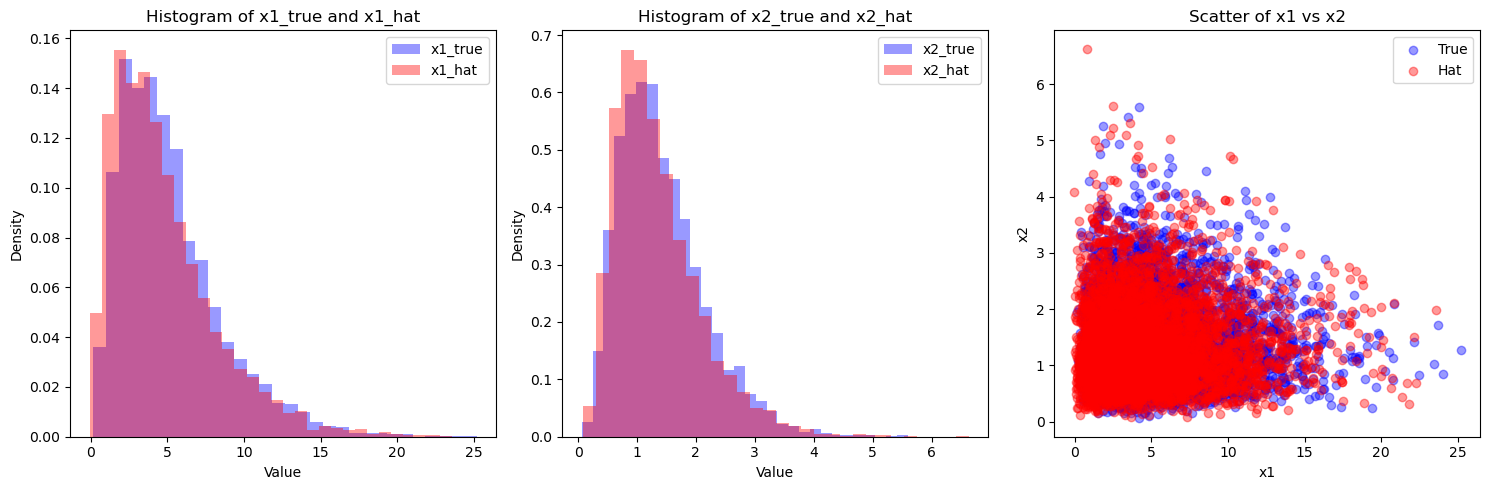

In [27]:
x1_true = generate_data(n_samples=5000, A_true=A_true[0].unsqueeze(0))
x1_hat = generate_data(n_samples=5000, A_true=torch.tensor(A_hat[0],dtype=torch.float32).unsqueeze(0))
x2_true = generate_data(n_samples=5000, A_true=A_true[1].unsqueeze(0))
x2_hat = generate_data(n_samples=5000, A_true=torch.tensor(A_hat[1],dtype=torch.float32).unsqueeze(0))
x1_true = x1_true[:, 0].numpy()  # Shape: (5000,)
x1_hat = x1_hat[:, 0].numpy()    # Shape: (5000,)
x2_true = x2_true[:, 0].numpy()  # Shape: (5000,)
x2_hat = x2_hat[:, 0].numpy()    # Shape: (5000,)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))  

axes[0].hist(x1_true, bins=30, color='blue', alpha=0.4, label='x1_true', density=True)
axes[0].hist(x1_hat, bins=30, color='red', alpha=0.4, label='x1_hat', density=True)
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Density')
axes[0].set_title('Histogram of x1_true and x1_hat')
axes[0].legend()

axes[1].hist(x2_true, bins=30, color='blue', alpha=0.4, label='x2_true', density=True)
axes[1].hist(x2_hat, bins=30, color='red', alpha=0.4, label='x2_hat', density=True)
axes[1].set_xlabel('Value')
axes[1].set_ylabel('Density')
axes[1].set_title('Histogram of x2_true and x2_hat')
axes[1].legend()

axes[2].scatter(x1_true, x2_true, color='blue', alpha=0.4, label='True')
axes[2].scatter(x1_hat, x2_hat, color='red', alpha=0.4, label='Hat')
axes[2].set_xlabel('x1')
axes[2].set_ylabel('x2')
axes[2].set_title('Scatter of x1 vs x2')
axes[2].legend()

plt.tight_layout()
plt.show()

In [ ]:
## the distributions of S1,S2 are unknown; noise-free ICA 

In [37]:
model_formula_X = "x1 <- s1 + s2; x2 <- s1 + s2"
model_formula_S = "u1, u2 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2);"
model_formula = model_formula_S + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=8e-3)
model.train()
niter = 4000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 3)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy()
            A_hat[j, :] = weights.flatten()

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 4.6624, s1: 4.6667, s2: 0.0085
Iter 1000 | loss: 1.8480, s1: 3.7261, s2: 3.7562
Iter 2000 | loss: 1.8532, s1: 3.4989, s2: 3.2916
Iter 3000 | loss: 1.8328, s1: 3.5481, s2: 3.4307
Iter 4000 | loss: 1.8331, s1: 3.5433, s2: 3.4204
Amari_error: 0.0657


In [39]:
print(A_true)
print(A_hat)

tensor([[2.3822, 1.3197],
        [0.4900, 1.5308]])
[[-0.56415749  0.14256643]
 [-0.11762071  0.21708757]]


In [ ]:
##the distributions of S1,S2 are unknown; homo_noisy ICA

In [41]:
n_components=2
cdn=5
A_true = generate_mixing_matrix(n_components, cdn)
Sigma=torch.diag(torch.tensor([0.25,0.49],dtype=torch.float32))
X = generate_data(n_samples=5000, A_true=A_true,Sigma=Sigma)

In [43]:
model_formula_X = "e1 ~ Normal(0.0, 0.5); e2 ~ Normal(0.0, 0.7); x1 <- 1*e1 + s1 + s2; x2 <- 1*e2 + s1 + s2"
model_formula_S = "u1, u2 ~ Uniform(0.0, 1.0); s1 <- n(u1); s2 <- n(u2);"
model_formula = model_formula_S + model_formula_X
model = SEM2(model_formula)
observed_var = ["x1", "x2"]
observed_index = [list(model.static_order()).index(var) for var in observed_var]
model = SEM2(model_formula)
optimizer = torch.optim.Adam(model.parameters(), lr=8e-3)
model.train()
niter = 4000
for i in range(niter):
    optimizer.zero_grad()
    sample = model(X.size(0) * 4)[:, observed_index]
    loss, s1, s2 = energy_loss(X, sample,beta=1)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

model.eval()

A_hat = np.zeros([len(observed_var), len(observed_var)])
with torch.no_grad(): 
    for j, node in enumerate(observed_var):
        if model.node_dict[node] is not None:
            weights = model.node_dict[node].weight_matrix()[0].detach().cpu().numpy().flatten()
            A_hat[j, :] = weights[1:(1+len(observed_var))]

AE = Amari_error(A_hat, A_true)
print(f"Amari_error: {AE:.4f}")

Iter 1 | loss: 2.1648, s1: 2.7015, s2: 1.0735
Iter 1000 | loss: 1.1865, s1: 2.3556, s2: 2.3383
Iter 2000 | loss: 1.1958, s1: 2.3498, s2: 2.3080
Iter 3000 | loss: 1.1899, s1: 2.3568, s2: 2.3339
Iter 4000 | loss: 1.1976, s1: 2.3516, s2: 2.3081
Amari_error: 0.0349


In [45]:
print(A_true)
print(A_hat)

tensor([[ 0.7424, -4.8104],
        [ 0.8444,  1.2633]])
[[ 0.4143464  -0.4142715 ]
 [-0.11786685 -0.45893005]]
